# Latent SDE Example

This notebook demonstrates using **LatentSDE** for stochastic time series modeling.

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from flax import nnx
import optax

import ldx

In [2]:
# Configuration
SEED = 42
N_SEQUENCES = 10
N_POINTS = 30
NOISE_STD = 0.15

LATENT_DIM = 4
HIDDEN_DIMS = (32, 32)
CONTEXT_DIM = 32
LEARNING_RATE = 1e-3
N_EPOCHS = 50
N_SAMPLES = 50

In [3]:
# Generate synthetic data - spiral trajectories with noise
key = jax.random.PRNGKey(SEED)

batch_times, batch_observations = ldx.datasets.generate_spiral_trajectory(
    n_points=N_POINTS,
    n_sequences=N_SEQUENCES,
    n_dims=2,
    noise_std=NOISE_STD,
    key=key
)

print(f"Generated {N_SEQUENCES} sequences with {N_POINTS} time points each")
print(f"Observation shape: {batch_observations.shape}")

Generated 10 sequences with 30 time points each
Observation shape: (10, 30, 2)


In [4]:
# Normalize data and create train/val split
normalized_obs, norm_params = ldx.utils.normalize_data(batch_observations, method="standard")

(train_obs, train_times), (val_obs, val_times) = ldx.utils.create_train_val_split(
    normalized_obs, batch_times, val_fraction=0.3
)

obs_dim = batch_observations.shape[2]
print(f"Training: {train_obs.shape[0]} sequences, Validation: {val_obs.shape[0]} sequences")

Training: 7 sequences, Validation: 3 sequences


In [5]:
# Create model
key, model_key = jax.random.split(key)
rngs = nnx.Rngs(model_key)

model = ldx.models.create_latent_sde(
    latent_dim=LATENT_DIM,
    obs_dim=obs_dim,
    hidden_dims=HIDDEN_DIMS,
    posterior_hidden_dims=HIDDEN_DIMS,
    prior_hidden_dims=HIDDEN_DIMS,
    diffusion_hidden_dims=(16, 16),
    context_dim=CONTEXT_DIM,
    encoder_type="mlp",
    decoder_type="mlp",
    use_linear_prior=False,
    rngs=rngs
)

print(f"Created LatentSDE with latent_dim={LATENT_DIM}, obs_dim={obs_dim}")

Created LatentSDE with latent_dim=4, obs_dim=2


In [6]:
# Setup training
optimizer = nnx.Optimizer(model, optax.adam(LEARNING_RATE), wrt=nnx.Param)

trainer = ldx.inference.VariationalTrainer(
    model=model,
    optimizer=optimizer,
    reconstruction_loss_fn=ldx.inference.reconstruction_loss_mse,
    beta_schedule=ldx.inference.create_beta_schedule("linear", warmup_steps=50)
)

In [7]:
# Training loop
train_losses = []
kl_losses = []

for epoch in range(N_EPOCHS):
    key, train_key = jax.random.split(key)
    train_idx = jax.random.randint(train_key, (), 0, train_obs.shape[0])
    
    model, train_metrics = trainer.train_step(
        model, train_obs[train_idx:train_idx+1], train_times[train_idx:train_idx+1], train_key, epoch
    )
    train_losses.append(float(train_metrics["total_loss"]))
    kl_losses.append(float(train_metrics["kl_loss"]))
    
    if epoch % 10 == 0:
        key, val_key = jax.random.split(key)
        val_idx = jax.random.randint(val_key, (), 0, val_obs.shape[0])
        val_metrics = trainer.evaluate(model, val_obs[val_idx:val_idx+1], val_times[val_idx:val_idx+1], val_key)
        print(f"Epoch {epoch:3d}: Train={train_metrics['total_loss']:.4f}, Val={val_metrics['total_loss']:.4f}, KL={train_metrics['kl_loss']:.4f}")

print("Training completed!")

Epoch   0: Train=1.8965, Val=38.4324, KL=21.5231
Epoch  10: Train=3.5344, Val=12.8847, KL=11.8108
Epoch  20: Train=3.2462, Val=3.9389, KL=6.3481
Epoch  30: Train=3.6403, Val=3.0535, KL=4.3378
Epoch  40: Train=2.5104, Val=1.7315, KL=2.0012
Training completed!


In [8]:
# Generate predictions with uncertainty
key, pred_key = jax.random.split(key)

val_sequence = val_obs[0]
val_times_seq = val_times[0]

# Get initial latent state
mean, logvar = model.encode(val_sequence[None, ...], val_times_seq)
key, sample_key = jax.random.split(key)
initial_state = model.reparameterize(mean[0], logvar[0], sample_key)

# Generate posterior samples (conditioned on observations)
keys = jax.random.split(sample_key, N_SAMPLES)

def sample_posterior_fn(k):
    return model.sample_posterior(initial_state, val_times_seq, val_sequence, k, return_kl=False)

posterior_samples = jax.vmap(sample_posterior_fn)(keys)
print(f"Generated {N_SAMPLES} posterior samples: {posterior_samples.shape}")

Generated 50 posterior samples: (50, 30, 4)


In [9]:
# Decode samples and compute metrics
val_obs_denorm = ldx.utils.denormalize_data(val_sequence, norm_params)
if val_obs_denorm.ndim > 2:
    val_obs_denorm = val_obs_denorm[0]

decoded_samples = []
for i in range(N_SAMPLES):
    decoded = model.decoder(posterior_samples[i])
    decoded_denorm = ldx.utils.denormalize_data(np.array(decoded), norm_params)
    while decoded_denorm.ndim > 2:
        decoded_denorm = decoded_denorm.squeeze()
    decoded_samples.append(decoded_denorm)

decoded_samples = np.array(decoded_samples)
mean_prediction = np.mean(decoded_samples, axis=0)

metrics = ldx.utils.compute_all_metrics(mean_prediction, np.array(val_obs_denorm))
print("Evaluation Metrics (Mean Prediction):")
for name, value in metrics.items():
    print(f"  {name.upper()}: {value:.4f}")

Evaluation Metrics (Mean Prediction):
  MSE: 0.0363
  MAE: 0.1467
  RMSE: 0.1904
  MAPE: 0.9284
  R2: 0.8454
  CORRELATION: 0.9588


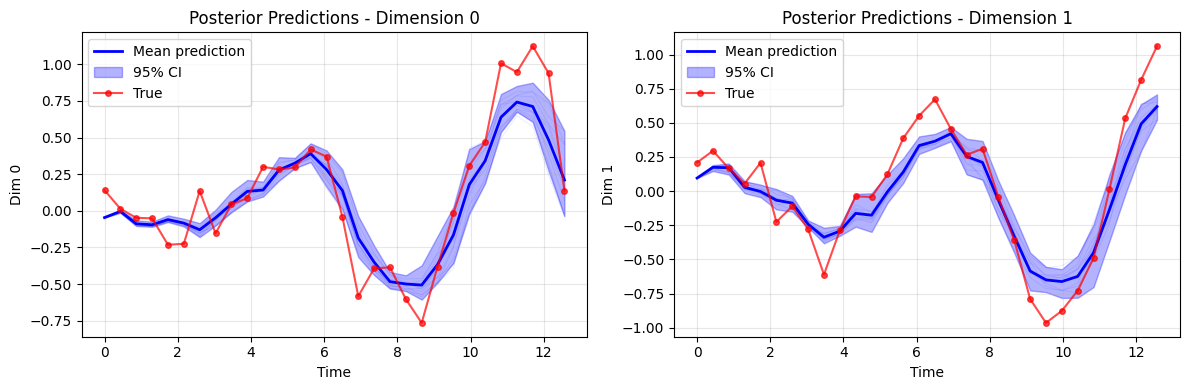

In [10]:
# Visualization - Posterior Predictions with Uncertainty
lower_bound = np.percentile(decoded_samples, 2.5, axis=0)
upper_bound = np.percentile(decoded_samples, 97.5, axis=0)

fig, axes = plt.subplots(1, obs_dim, figsize=(6 * obs_dim, 4))
if obs_dim == 1:
    axes = [axes]

for dim in range(obs_dim):
    ax = axes[dim]
    
    # Plot individual samples
    for i in range(min(10, N_SAMPLES)):
        ax.plot(val_times_seq, decoded_samples[i, :, dim], alpha=0.1, color='blue', linewidth=0.5)
    
    # Plot mean and confidence interval
    ax.plot(val_times_seq, mean_prediction[:, dim], color='blue', linewidth=2, label='Mean prediction')
    ax.fill_between(val_times_seq, lower_bound[:, dim], upper_bound[:, dim], alpha=0.3, color='blue', label='95% CI')
    
    # Plot ground truth
    ax.plot(val_times_seq, val_obs_denorm[:, dim], 'ro-', alpha=0.7, linewidth=1.5, markersize=4, label='True')
    
    ax.set_xlabel('Time')
    ax.set_ylabel(f'Dim {dim}')
    ax.set_title(f'Posterior Predictions - Dimension {dim}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()